# 단진자의 진폭에 따른 주기 보정항
작은 진폭 근사 주기 $T_0 = 2\pi\sqrt{L/g}$에 대해 실제 주기는 $T = T_0 C(\theta_0)$입니다.

보정항의 정확한 식은 $C(\theta_0) = \frac{2}{\pi}K(\sin^2(\theta_0/2))$이며, $K(m)$은 매개변수 $m$을 사용하는 제1종 완전 타원 적분입니다. 각도는 식 안에서 라디안으로 변환하며, $C(0)=1$입니다. 공기 저항이 없고 줄의 질량을 무시하는 이상적인 단진자를 가정합니다.

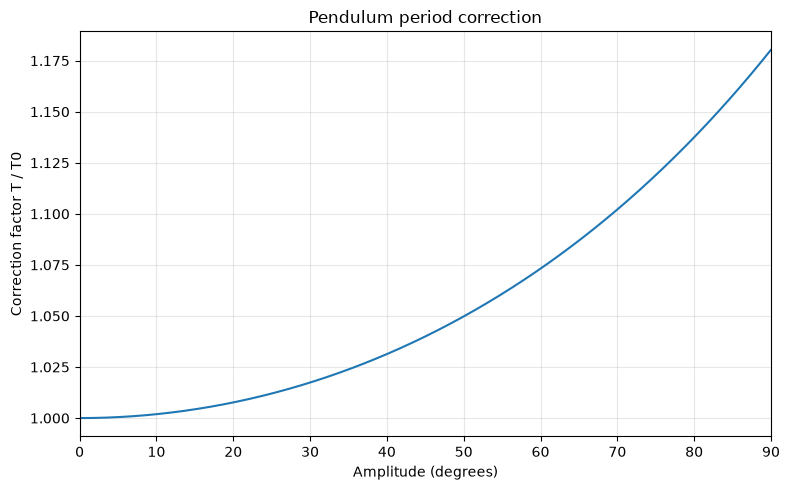

진폭 10°: 보정항 = 1.0019071881
진폭 30°: 보정항 = 1.0174087976


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ellipk

def correction(amplitude_deg):
    amplitude_rad = np.deg2rad(amplitude_deg)
    return 2 / np.pi * ellipk(np.sin(amplitude_rad / 2) ** 2)

assert np.isclose(correction(0), 1.0)
assert 1 < correction(10) < correction(30) < correction(90)

amplitudes = np.linspace(0, 90, 901)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(amplitudes, correction(amplitudes))
ax.set(xlabel='Amplitude (degrees)', ylabel='Correction factor T / T0',
       title='Pendulum period correction', xlim=(0, 90))
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

for angle in (10, 30):
    print(f'진폭 {angle}°: 보정항 = {correction(angle):.10f}')